In [1]:
import zipfile
import os

zip_path = "gesture-recognition-and-biometrics-electromyogram-grabmyo-1.1.0.zip"
extract_dir = "grabmyo_dataset"

# Create extraction folder
os.makedirs(extract_dir, exist_ok=True)

# Extract all contents
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extracted files:")
os.listdir(extract_dir)


Extracted files:


['gesture-recognition-and-biometrics-electromyogram-grabmyo-1.1.0']

In [2]:
# emg_id_cnn.py
import os, math, glob, json, random
import numpy as np
import pandas as pd
from typing import Tuple, List, Dict
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# -----------------------------
# Utilities
# -----------------------------
def bandpass_notch(x, fs=200, bp=(20,450), notch=None):
    # x: (T, C). Implement with scipy if available; here we keep it as a no-op placeholder.
    # Replace with proper filters in your pipeline (scipy.signal butter + filtfilt, + iirnotch).
    return x

def zscore_per_channel(x, mean, std, eps=1e-8):
    return (x - mean) / (std + eps)

def compute_channel_stats(arrays: List[np.ndarray]) -> Tuple[np.ndarray, np.ndarray]:
    # arrays: list of (T, C)
    concat = np.concatenate(arrays, axis=0)  # (sumT, C)
    mean = concat.mean(axis=0)
    std  = concat.std(axis=0)
    return mean, std

def load_emg_array(path: str) -> np.ndarray:
    # Expect .npy with shape (T, 8). Modify if you store CSV.
    # If CSV: use np.loadtxt(path, delimiter=',') or pandas.read_csv(...).values
    return np.load(path)

# -----------------------------
# Windowing Dataset
# -----------------------------
class EMGWindows(Dataset):
    def __init__(self, meta: pd.DataFrame, label_encoder: LabelEncoder,
                 sessions_for_stats: List[int], window_ms=200, fs=200, overlap=0.5,
                 apply_filter=False, notch=None, channel_stats: Dict[str, np.ndarray]=None,
                 augment=False):
        """
        meta: DataFrame with [path, session, subject, gesture]
        sessions_for_stats: which sessions are used to fit normalization stats
        channel_stats: if provided, dict with 'mean' (8,), 'std' (8,)
        """
        self.meta = meta.reset_index(drop=True)
        self.le = label_encoder
        self.fs = fs
        self.win = int(round(window_ms * fs / 1000))
        self.hop = max(1, int(round(self.win * (1 - overlap))))
        self.apply_filter = apply_filter
        self.notch = notch
        self.augment = augment

        # Load all arrays once and pre-window
        self.samples = []  # list of (C, T), label_id
        self.labels = []
        raw_for_stats = []

        # Preload arrays and (optionally) accumulate for stats
        cache = {}
        for i, row in self.meta.iterrows():
            p = row['path']
            if p not in cache:
                arr = load_emg_array(p)  # (T, 8)
                if self.apply_filter:
                    arr = bandpass_notch(arr, fs=self.fs, bp=(20,450), notch=self.notch)
                cache[p] = arr
            arr = cache[p]
            # Collect for stats only from specified sessions
            if int(row['session']) in sessions_for_stats:
                raw_for_stats.append(arr)

        # Fit or use provided channel stats
        if channel_stats is None:
            mean, std = compute_channel_stats(raw_for_stats if raw_for_stats else [np.zeros((1,8))])
            self.stats = {'mean': mean.astype(np.float32), 'std': std.astype(np.float32)}
        else:
            self.stats = channel_stats

        # Now window all recordings
        for i, row in self.meta.iterrows():
            p, sess, subj = row['path'], int(row['session']), str(row['subject'])
            y = self.le.transform([subj])[0]
            arr = cache[p]  # (T, 8)

            # Normalize with train stats
            arr = zscore_per_channel(arr, self.stats['mean'], self.stats['std'])

            T = arr.shape[0]
            for start in range(0, max(0, T - self.win + 1), self.hop):
                w = arr[start:start+self.win]                 # (win, 8)
                w = w.T.astype(np.float32, copy=False)       # (C=8, T)
                self.samples.append(w)
                self.labels.append(y)

        self.samples = np.stack(self.samples)  # (N, C, T)
        self.labels  = np.array(self.labels, dtype=np.int64)

    def __len__(self):
        return len(self.labels)

    def channel_dropout(self, x, p=0.1):
        # x: (C,T)
        if random.random() < p:
            c = random.randrange(x.shape[0])
            x[c, :] = 0.0
        return x

    def gaussian_noise(self, x, std=0.02):
        return x + np.random.randn(*x.shape).astype(np.float32)*std

    def time_jitter(self, x, max_shift=2):
        # shift along time axis by -max_shift..+max_shift samples
        s = random.randint(-max_shift, max_shift)
        if s == 0: return x
        if s > 0:
            return np.concatenate([x[:, s:], np.zeros((x.shape[0], s), dtype=x.dtype)], axis=1)
        else:
            s = abs(s)
            return np.concatenate([np.zeros((x.shape[0], s), dtype=x.dtype), x[:, :-s]], axis=1)

    def __getitem__(self, idx):
        x = self.samples[idx].copy()
        y = self.labels[idx]
        if self.augment:
            if random.random() < 0.5: x = self.gaussian_noise(x, std=0.01)
            if random.random() < 0.3: x = self.channel_dropout(x, p=1.0)  # drop exactly one channel sometimes
            if random.random() < 0.3: x = self.time_jitter(x, max_shift=2)
        return torch.from_numpy(x), torch.tensor(y)

# -----------------------------
# 2D CNN over (Channels x Time)
# -----------------------------
class EMG2DCNN(nn.Module):
    def __init__(self, n_classes: int, in_ch=1):
        super().__init__()
        # Treat (C=8, T) as an "image": add a fake 1 channel dim -> (N, 1, 8, T)
        self.features = nn.Sequential(
            nn.Conv2d(in_ch, 16, kernel_size=(3,5), padding=(1,2)),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2,2)),     # -> (16, 4, T/2)

            nn.Conv2d(16, 32, kernel_size=(3,5), padding=(1,2)),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2,2)),     # -> (32, 2, T/4)

            nn.Conv2d(32, 64, kernel_size=(2,3), padding=(0,1)),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.AdaptiveMaxPool2d((1, 8)),        # -> (64, 1, 8)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                         # 64*1*8 = 512
            nn.Dropout(p=0.3),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(256, n_classes)
        )

    def forward(self, x):
        # x: (N, C=8, T) -> add channel dim
        x = x.unsqueeze(1)           # (N,1,8,T)
        x = self.features(x)
        x = self.classifier(x)
        return x

# -----------------------------
# Train / Eval
# -----------------------------
def train_epoch(model, loader, optim, loss_fn, device):
    model.train()
    total, correct, loss_sum = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optim.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optim.step()
        loss_sum += loss.item() * yb.size(0)
        preds = torch.argmax(logits, dim=1)
        correct += (preds == yb).sum().item()
        total += yb.size(0)
    return loss_sum/total, correct/total

@torch.no_grad()
def eval_epoch(model, loader, device):
    model.eval()
    all_y, all_p = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        logits = model(xb)
        preds = torch.argmax(logits, dim=1).cpu().numpy().tolist()
        all_p.extend(preds)
        all_y.extend(yb.numpy().tolist())
    acc = accuracy_score(all_y, all_p)
    f1  = f1_score(all_y, all_p, average='macro')
    return acc, f1

def make_label_encoder(subject_list: List[str]) -> LabelEncoder:
    le = LabelEncoder()
    le.fit(subject_list)
    return le

# -----------------------------
# Entry: provide your metadata CSV
# -----------------------------
def main(meta_csv: str, out_dir="runs_emg_id",
         window_ms=200, fs=200, overlap=0.5,
         batch_size=256, epochs=30, lr=1e-3, weight_decay=1e-4,
         train_sessions=(1,2), test_session=3, augment=True):

    os.makedirs(out_dir, exist_ok=True)
    meta = pd.read_csv(meta_csv)  # columns: path, session, subject, gesture
    meta['session'] = meta['session'].astype(int)
    subjects = sorted(meta['subject'].unique().tolist())
    le = make_label_encoder(subjects)
    n_classes = len(subjects)

    train_meta = meta[meta.session.isin(train_sessions)].copy()
    test_meta  = meta[meta.session == test_session].copy()

    # Build train dataset to estimate normalization stats from train sessions only
    tmp_ds = EMGWindows(train_meta, le, sessions_for_stats=list(train_sessions),
                        window_ms=window_ms, fs=fs, overlap=overlap,
                        apply_filter=False, notch=None, augment=False)
    stats = tmp_ds.stats  # {'mean':(8,), 'std':(8,)}

    # Rebuild with augmentation + fixed stats
    train_ds = EMGWindows(train_meta, le, sessions_for_stats=list(train_sessions),
                          window_ms=window_ms, fs=fs, overlap=overlap,
                          apply_filter=False, notch=None, augment=augment,
                          channel_stats=stats)
    test_ds  = EMGWindows(test_meta,  le, sessions_for_stats=list(train_sessions),
                          window_ms=window_ms, fs=fs, overlap=overlap,
                          apply_filter=False, notch=None, augment=False,
                          channel_stats=stats)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = EMG2DCNN(n_classes=n_classes).to(device)

    # Optional: class weights if subjects are imbalanced by window count
    class_counts = np.bincount(train_ds.labels, minlength=n_classes)
    weights = (class_counts.sum() / (class_counts + 1e-8))
    weights = weights / weights.mean()
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=device))

    optim = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optim, mode='max', factor=0.5, patience=3, verbose=False)

    best = {'acc': 0.0, 'f1': 0.0, 'epoch': -1}
    for ep in range(1, epochs+1):
        tr_loss, tr_acc = train_epoch(model, train_loader, optim, loss_fn, device)
        te_acc, te_f1   = eval_epoch(model, test_loader, device)
        scheduler.step(te_acc)

        print(f"Epoch {ep:02d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | test acc {te_acc:.3f} f1 {te_f1:.3f}")

        if te_acc > best['acc']:
            best = {'acc': te_acc, 'f1': te_f1, 'epoch': ep}
            torch.save({
                'model': model.state_dict(),
                'label_encoder_classes': subjects,
                'stats': stats,
                'cfg': {
                    'window_ms': window_ms, 'fs': fs, 'overlap': overlap
                }
            }, os.path.join(out_dir, f'best_ep{ep:02d}_acc{te_acc:.3f}.pt'))

    print("Best:", best)

if __name__ == "__main__":
    # Example:
    # python emg_id_cnn.py meta.csv
    import argparse
    ap = argparse.ArgumentParser()
    ap.add_argument("meta_csv", type=str, help="CSV with columns: path,session,subject,gesture")
    ap.add_argument("--out_dir", type=str, default="runs_emg_id")
    ap.add_argument("--window_ms", type=int, default=200)
    ap.add_argument("--fs", type=int, default=200)
    ap.add_argument("--overlap", type=float, default=0.5)
    ap.add_argument("--batch_size", type=int, default=256)
    ap.add_argument("--epochs", type=int, default=30)
    ap.add_argument("--lr", type=float, default=1e-3)
    ap.add_argument("--weight_decay", type=float, default=1e-4)
    ap.add_argument("--train_sessions", type=int, nargs="+", default=[1,2])
    ap.add_argument("--test_session", type=int, default=3)
    ap.add_argument("--augment", action="store_true")
    args = ap.parse_args()
    main(**vars(args))


usage: ipykernel_launcher.py [-h] [--out_dir OUT_DIR] [--window_ms WINDOW_MS] [--fs FS] [--overlap OVERLAP]
                             [--batch_size BATCH_SIZE] [--epochs EPOCHS] [--lr LR] [--weight_decay WEIGHT_DECAY]
                             [--train_sessions TRAIN_SESSIONS [TRAIN_SESSIONS ...]] [--test_session TEST_SESSION]
                             [--augment]
                             meta_csv
ipykernel_launcher.py: error: unrecognized arguments: -f


SystemExit: 2

C:\Users\User\anaconda3\Lib\site-packages\IPython\core\interactiveshell.py:3585: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [3]:
if __name__ == "__main__":
    import sys, os

    # Check if running inside IPython or Jupyter
    if any("ipykernel_launcher" in arg for arg in sys.argv):
        print("Detected Jupyter/IPython environment — running with default args.")
        main(
            meta_csv="meta.csv",  # <-- change this to your actual file
            out_dir="runs_emg_id",
            window_ms=200,
            fs=200,
            overlap=0.5,
            batch_size=256,
            epochs=30,
            lr=1e-3,
            weight_decay=1e-4,
            train_sessions=[1, 2],
            test_session=3,
            augment=True
        )
    else:
        import argparse
        ap = argparse.ArgumentParser()
        ap.add_argument("meta_csv", type=str, help="CSV with columns: path,session,subject,gesture")
        ap.add_argument("--out_dir", type=str, default="runs_emg_id")
        ap.add_argument("--window_ms", type=int, default=200)
        ap.add_argument("--fs", type=int, default=200)
        ap.add_argument("--overlap", type=float, default=0.5)
        ap.add_argument("--batch_size", type=int, default=256)
        ap.add_argument("--epochs", type=int, default=30)
        ap.add_argument("--lr", type=float, default=1e-3)
        ap.add_argument("--weight_decay", type=float, default=1e-4)
        ap.add_argument("--train_sessions", type=int, nargs="+", default=[1, 2])
        ap.add_argument("--test_session", type=int, default=3)
        ap.add_argument("--augment", action="store_true")
        args = ap.parse_args()
        main(**vars(args))


Detected Jupyter/IPython environment — running with default args.


FileNotFoundError: [Errno 2] No such file or directory: 'meta.csv'

In [2]:
for root, dirs, files in os.walk(extract_dir):
    print(root)
    for file in files:
        print("   ", file)


grabmyo_dataset
grabmyo_dataset\gesture-recognition-and-biometrics-electromyogram-grabmyo-1.1.0
    DeviceInfo.pdf
    Electrodelocation.pdf
    featiDFTl.m
    GestureList.JPG
    grabmyo_convert_wfdb_to_mat.py
    grabmyo_feature_extraction.m
    grabmyo_visualize.py
    LICENSE.txt
    MotionSequence.txt
    readme.txt
    RECORDS
    segmentEMG.m
    SHA256SUMS.txt
    subject-info.csv
grabmyo_dataset\gesture-recognition-and-biometrics-electromyogram-grabmyo-1.1.0\Session1
grabmyo_dataset\gesture-recognition-and-biometrics-electromyogram-grabmyo-1.1.0\Session1\session1_participant1
    session1_participant1_gesture10_trial1.dat
    session1_participant1_gesture10_trial1.hea
    session1_participant1_gesture10_trial2.dat
    session1_participant1_gesture10_trial2.hea
    session1_participant1_gesture10_trial3.dat
    session1_participant1_gesture10_trial3.hea
    session1_participant1_gesture10_trial4.dat
    session1_participant1_gesture10_trial4.hea
    session1_participant1_gestu

In [3]:
pip install wfdb numpy pandas matplotlib scikit-learn scipy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


dict_keys(['record_name', 'n_sig', 'fs', 'counter_freq', 'base_counter', 'sig_len', 'base_time', 'base_date', 'comments', 'sig_name', 'p_signal', 'd_signal', 'e_p_signal', 'e_d_signal', 'file_name', 'fmt', 'samps_per_frame', 'skew', 'byte_offset', 'adc_gain', 'baseline', 'units', 'adc_res', 'adc_zero', 'init_value', 'checksum', 'block_size'])
Channels: ['F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'F9', 'F10', 'F11', 'F12', 'F13', 'F14', 'F15', 'F16', 'U1', 'W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'U2', 'U3', 'W7', 'W8', 'W9', 'W10', 'W11', 'W12', 'U4']
Sampling Frequency: 2048
Signal Shape: (10240, 32)


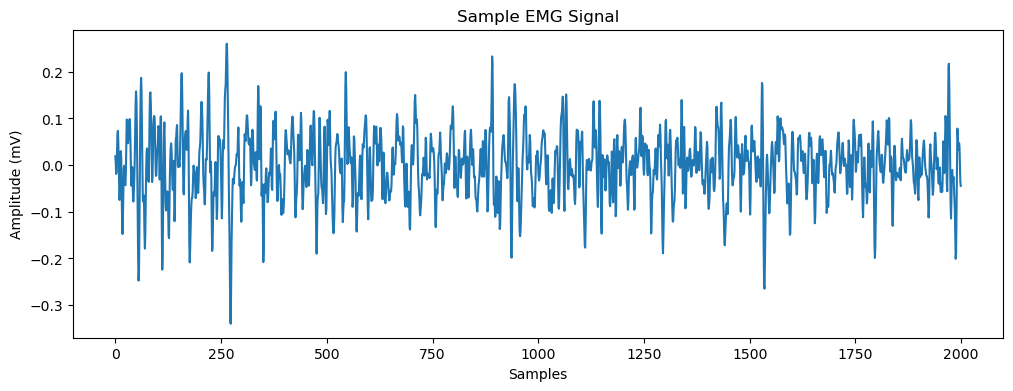

In [4]:
import wfdb
import os
import matplotlib.pyplot as plt

base_path = "grabmyo_dataset/gesture-recognition-and-biometrics-electromyogram-grabmyo-1.1.0/Session1/session1_participant1"

# Pick one file (without .hea or .dat)
record_name = os.path.join(base_path, "session1_participant1_gesture10_trial1")

record = wfdb.rdrecord(record_name)

print(record.__dict__.keys())
print("Channels:", record.sig_name)
print("Sampling Frequency:", record.fs)
print("Signal Shape:", record.p_signal.shape)

# Plot the first few seconds of EMG
plt.figure(figsize=(12, 4))
plt.plot(record.p_signal[:2000, 0])
plt.title("Sample EMG Signal")
plt.xlabel("Samples")
plt.ylabel("Amplitude (mV)")
plt.show()


                 F1            F2            F3            F4            F5  \
count  10240.000000  10240.000000  10240.000000  10240.000000  10240.000000   
mean      -0.000007      0.000011      0.000016     -0.000041     -0.000035   
std        0.047928      0.064370      0.077382      0.074592      0.078213   
min       -0.339843     -0.401372     -0.585434     -0.750531     -0.488200   
25%       -0.026828     -0.035061     -0.040546     -0.039008     -0.042680   
50%        0.001483      0.001730      0.001505      0.002281      0.001754   
75%        0.028446      0.037433      0.042748      0.041793      0.046517   
max        0.260136      0.369968      0.510152      0.505811      0.494211   

                 F6            F7            F8            F9           F10  \
count  10240.000000  10240.000000  10240.000000  10240.000000  10240.000000   
mean      -0.000097     -0.000010     -0.000016     -0.000016      0.000014   
std        0.075557      0.052695      0.043968    

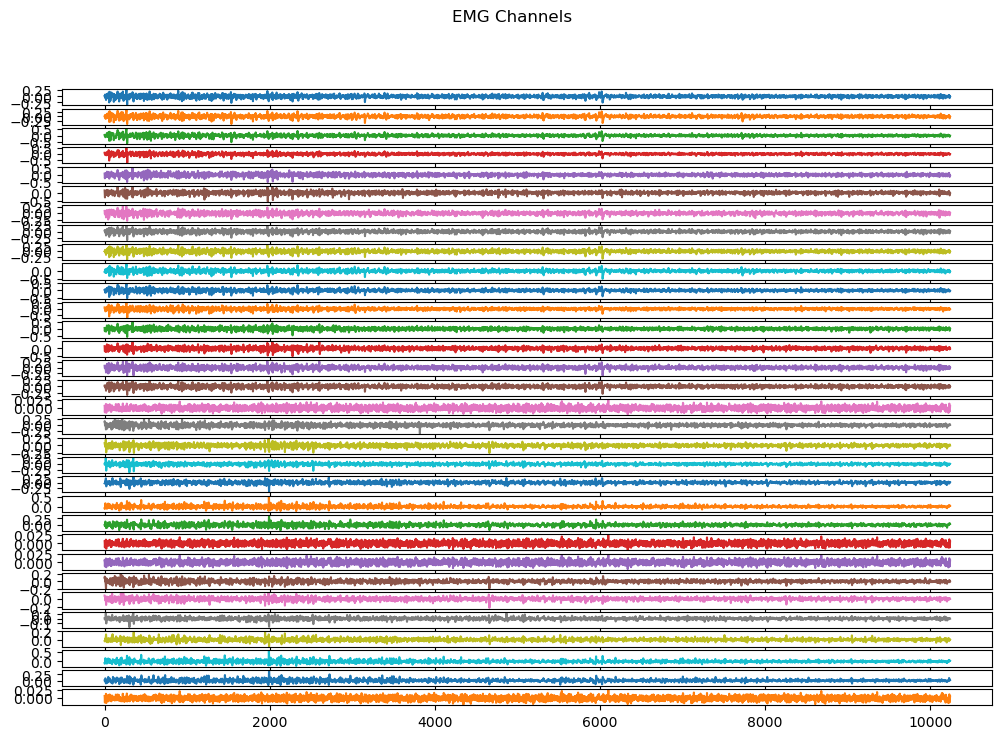

In [5]:
import numpy as np
import pandas as pd

signal = record.p_signal
df = pd.DataFrame(signal, columns=record.sig_name)

print(df.describe())  # Summary stats
df.plot(subplots=True, figsize=(12, 8), legend=False, title="EMG Channels")
plt.show()


In [6]:
from scipy.stats import skew, kurtosis

def extract_features(signal):
    feats = {}
    for i in range(signal.shape[1]):
        channel = signal[:, i]
        feats[f"mean_ch{i}"] = np.mean(channel)
        feats[f"std_ch{i}"] = np.std(channel)
        feats[f"rms_ch{i}"] = np.sqrt(np.mean(channel**2))
        feats[f"skew_ch{i}"] = skew(channel)
        feats[f"kurtosis_ch{i}"] = kurtosis(channel)
    return feats


In [7]:
import glob

data = []

for participant_folder in glob.glob("grabmyo_dataset/**/session1_participant*", recursive=True):
    participant_id = participant_folder.split("_participant")[-1].split(os.sep)[0]
    
    for hea_file in glob.glob(os.path.join(participant_folder, "*.hea")):
        record_name = hea_file[:-4]
        record = wfdb.rdrecord(record_name)
        feats = extract_features(record.p_signal)
        feats["participant_id"] = participant_id
        data.append(feats)

df_features = pd.DataFrame(data)
df_features.head()


,mean_ch0,std_ch0,rms_ch0,skew_ch0,kurtosis_ch0,mean_ch1,std_ch1,rms_ch1,skew_ch1,kurtosis_ch1,...,std_ch30,rms_ch30,skew_ch30,kurtosis_ch30,mean_ch31,std_ch31,rms_ch31,skew_ch31,kurtosis_ch31,participant_id
0,-0.000007,0.047925,0.047925,-0.264655,2.574033,1.090949e-05,0.064367,0.064367,-0.268170,2.737365,...,0.045426,0.045426,0.585164,3.683970,-0.000007,0.005259,0.005259,0.068160,0.030816,1
1,0.000042,0.057235,0.057235,-1.051270,16.942218,5.478721e-05,0.070744,0.070744,-1.121841,18.265982,...,0.033784,0.033784,0.330375,7.672553,0.000004,0.005121,0.005121,0.062297,0.018950,1
2,0.000031,0.039620,0.039620,-0.634328,3.795827,4.641456e-05,0.049239,0.049239,-0.723340,4.554194,...,0.035553,0.035553,0.403721,2.516949,0.000006,0.005027,0.005027,0.032977,-0.050155,1
3,0.000005,0.068228,0.068228,-0.588082,6.938354,1.154374e-05,0.080734,0.080734,-0.594151,7.753831,...,0.059792,0.059792,0.378922,2.347303,0.000004,0.005212,0.005212,0.066974,0.043904,1
4,0.000005,0.060540,0.060540,-0.421295,2.379207,9.085645e-07,0.075170,0.075170,-0.392559,2.061099,...,0.073988,0.073988,0.428400,4.008699,0.000006,0.005151,0.005151,0.098694,0.096034,1


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

X = df_features.drop("participant_id", axis=1)
y = df_features["participant_id"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           1       0.69      0.94      0.79        31
          10       0.61      0.41      0.49        27
          11       0.78      0.72      0.75        25
          12       0.89      0.64      0.74        25
          13       0.68      0.60      0.64        25
          14       0.92      0.88      0.90        26
          15       0.69      0.29      0.41        31
          16       0.75      0.41      0.53        22
          17       0.86      0.83      0.84        23
          18       0.75      0.82      0.78        22
          19       0.82      0.64      0.72        22
           2       0.69      0.92      0.79        24
          20       0.91      0.91      0.91        22
          21       0.67      0.82      0.74        17
          22       0.93      0.81      0.87        32
          23       0.84      0.95      0.89        22
          24       1.00      0.67      0.80        18
          25       0.71    

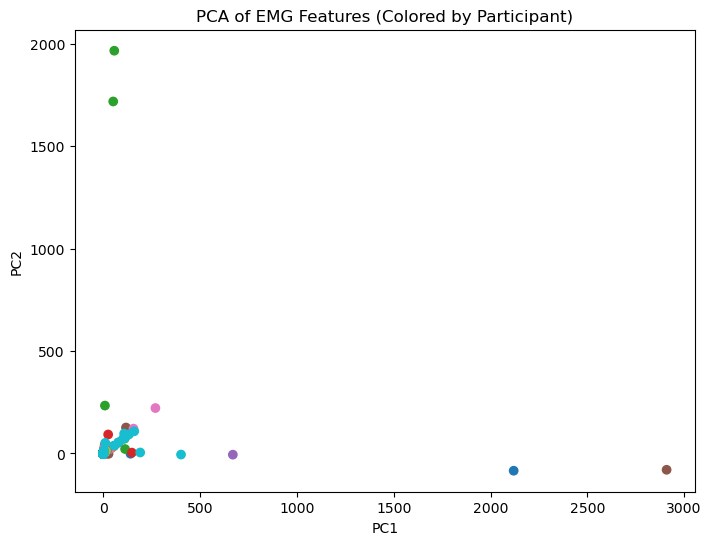

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
components = pca.fit_transform(X)

plt.figure(figsize=(8,6))
plt.scatter(components[:,0], components[:,1], c=pd.factorize(y)[0], cmap="tab10")
plt.title("PCA of EMG Features (Colored by Participant)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()
